# Workbook for toy model

Workbook at vault `vac-metad-work > workbooks > timescales-workbook`
$$
 C_u(\tau) = 0.7\,\text{e}^{-\tau/1440} + 0.1\,\text{e}^{-\tau/60} + 0.1\,\text{e}^{-\tau/26} + 0.1\,\text{e}^{-\tau/2}
$$

## Step 3 - Three summary times of one ACF
$$
\tau_0 = -\frac{1}{C_u'(0)},\qquad \tau_{\rm int} = \int_0^\infty C_u(\tau)\,d\tau,\qquad \tau_{{\rm exp},u} = -\Big[\lim_{\tau\to\infty}\frac{d\ln C_u}{d\tau}\Big]^{-1}.
$$

### 3(c) Evaluate all three for the toy. For each, which mode contributes most?

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from vac_metad.acf_toy import toy_model_acf


def print_tau_0(acf, msg=""):
    ans = 1 / np.sum(acf.coeffs / acf.timescales)
    print(f"tau_0 = {ans:.2f} ps   {msg}")


def print_tau_int(acf, msg=""):
    ans = np.sum(acf.coeffs * acf.timescales)
    print(f"tau_int = {ans:.2f} ps   {msg}")


def print_tau_exp(acf, msg=""):
    print(f"tau_exp = {acf.timescales[0]:.2f} ps   {msg}")


taus = np.linspace(0, 2000, 200)
acf = toy_model_acf(taus)
print_tau_0(acf, msg="    dominated by mixture of t_2, t_3")
print_tau_int(acf, msg="dominated by t_1, tempered by t_2")
print_tau_exp(acf, msg="straight t_1")

tau_0 = 17.89 ps       dominated by mixture of t_2, t_3
tau_int = 1303.80 ps   dominated by t_1, tempered by t_2
tau_exp = 1850.00 ps   straight t_1


## Step 4 · $\tau_0$ belongs to your frame spacing

You never have $C_u'(0)$. What you can compute is the chord at one frame, $t_u(\Delta t) = -\Delta t/\ln\hat C_u(\Delta t)$.


- (a) Compute the one-frame chord of the toy for $\Delta t$ = 0.1, 1, 2, 10 and 100 ps.
- (b) Show that it tends to $\tau_0$ as $\Delta t \to 0$. How small must $\Delta t$ be?

In [5]:
from vac_metad.acf_toy import acf_terms

for dt in (0.001, 0.01, 0.1, 1, 2, 10, 100):
    ct = np.sum(acf_terms(dt))
    tau0 = dt / (1 - ct)
    print(f"{dt = } ps,\t {tau0 = :.3f} ps")

dt = 0.001 ps,	 tau0 = 17.896 ps
dt = 0.01 ps,	 tau0 = 17.932 ps
dt = 0.1 ps,	 tau0 = 18.297 ps
dt = 1 ps,	 tau0 = 22.148 ps
dt = 2 ps,	 tau0 = 26.791 ps
dt = 10 ps,	 tau0 = 66.498 ps
dt = 100 ps,	 tau0 = 316.646 ps


## Step 5 · $\tau_{\rm int}$ is a statistics time

This is not from the workbook, but from a separate claude query.

**Computing $\tau_{\rm int}$ and choosing a window**
1. **Running integral.** Plot $\tau_{\rm int}(W) = \Delta t\,[\tfrac12 + \sum_{k=1}^{W}\rho_k]$ against $W$ on a log axis. Watch it climb in steps, one per mode, and level off at 1016.8 ps. Which part of the curve does each $t_i$ fill in?

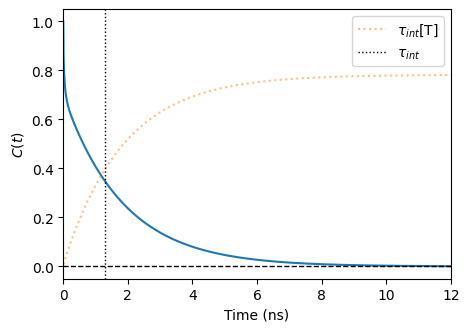

In [ ]:
taus = np.linspace(0, 20000, 2000)
dt = taus[1] - taus[0]
acf = toy_model_acf(taus)

# exact tau_int
tau_int = np.sum(acf.coeffs * acf.timescales)

# tau_int computed over time windows
tau_int_w = dt * (0.5 + np.cumsum(acf.ct[1:]))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(taus / 1000, acf.ct)
ax.plot(
    taus[1:] / 1000, tau_int_w * 0.0006, ls=":", alpha=0.5, label=r"$\tau_{int}$[T]"
)
ax.axvline(x=tau_int / 1000, ls=":", color="k", lw=1, label=r"$\tau_{int}$")
ax.axhline(y=0, ls="--", color="k", lw=1)
ax.set_xlabel("Time (ns)")
ax.set_ylabel(r"$C(t)$")
ax.set_xlim(0, 12)
ax.legend()

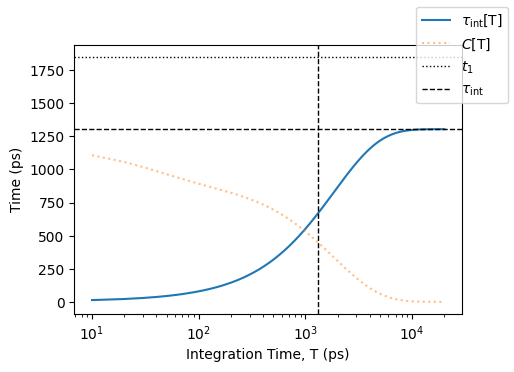

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogx(taus[1:], tau_int_w, label=r"$\tau_\mathrm{int}$[T]")
ax.semilogx(taus[1:], tau_int * acf.ct[1:], ls=":", label=r"$C$[T]", alpha=0.5)
ax.axhline(y=acf.timescales[0], ls=":", color="k", lw=1, label=r"$t_1$")
label = r"$\tau_\mathrm{int}$"
ax.axhline(y=tau_int, ls="--", color="k", lw=1, label=label)
ax.axvline(x=tau_int, ls="--", color="k", lw=1)
ax.set_xlabel("Integration Time, T (ps)")
ax.set_ylabel("Time (ps)")
fig.legend()

2. **The Sokal window as a graphical rule.** Draw the line $W\Delta t/c$ on the same plot. The window is where the running integral first lies above that line. Try $c$ = 3, 5, 8, 10, and find the truncation bias at each $c$. Then check it against $a_1 t_1 e^{-W/t_1}$.

Sokal adds one twist: the rule is self-consistent. You want to stop at $T_w = c\,\tau_{\rm int}$, but you don’t know $\tau_{\rm int}$ yet, since that’s what you’re computing. So you use the running estimate and stop at the first $T_w$ that satisfies

$$T_w \ \ge\ c\,\tau_{\rm int}(T_w).$$

$c$-parameter:  Going out farther adds noise.  The bias is the tail that is missed:

$$\int_{T_w}^\infty dt \hat{C}_u(t) \propto e^{-c}$$

In [7]:
# from vac_metad.acf import auto_window as sokal_window
def sokal_window(times_w, tau_int_w, c):
    ok = times_w >= c * tau_int_w
    if not ok.any():
        return np.nan, np.nan  # window never closed: need longer lags
    i = np.argmax(ok)
    return times_w[i], tau_int_w[i]


print(f"Exact {tau_int = :.1f}")
for c in (1, 3, 5, 8, 10, 20):
    T_w, t_int_w = sokal_window(taus[1:], tau_int_w, c)
    error = np.abs(t_int_w - tau_int) / tau_int
    print(
        f"{c = }\t{T_w = :.1f}\t tau_int = {t_int_w:.1f}\t{error = :.1%}\t 3.5 exp(-c) = {3.5 * np.exp(-c):.1%}"
    )

Exact tau_int = 1303.8
c = 1	T_w = 30.0	 tau_int = 29.4	error = 97.7%	 3.5 exp(-c) = 128.8%
c = 3	T_w = 3241.6	 tau_int = 1080.2	error = 17.1%	 3.5 exp(-c) = 17.4%
c = 5	T_w = 6313.2	 tau_int = 1261.6	error = 3.2%	 3.5 exp(-c) = 2.4%
c = 8	T_w = 10405.2	 tau_int = 1299.5	error = 0.3%	 3.5 exp(-c) = 0.1%
c = 10	T_w = 13036.5	 tau_int = 1303.0	error = 0.1%	 3.5 exp(-c) = 0.0%
c = 20	T_w = nan	 tau_int = nan	error = nan%	 3.5 exp(-c) = 0.0%


3. **Tail correction.** Add the missing tail analytically, $\tau_{\rm int}(W) + a_1 t_1 e^{-W/t_1}$, and compare with simply taking a bigger $c$.

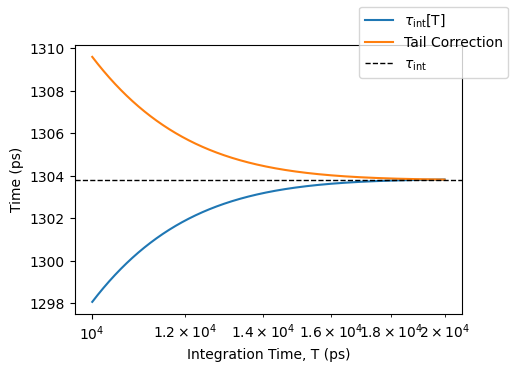

In [8]:
start = 1000  # start plotting out near tail
shift = 0.3  # shift to correct for systematic error due to concavity of C(t)

t = taus[start:]
tiw = tau_int_w[start - 1 :] - shift
tail = acf.coeffs[0] * acf.timescales[0] * np.exp(-t / acf.timescales[0])

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.semilogx(t, tiw, label=r"$\tau_\mathrm{int}$[T]")
ax.semilogx(t, tail + tau_int, label=r"Tail Correction")
ax.axhline(y=tau_int, ls="--", color="k", lw=1, label=r"$\tau_\mathrm{int}$")
ax.set_xlabel("Integration Time, T (ps)")
ax.set_ylabel("Time (ps)")
fig.legend()

**Why a window is needed at all (bias against variance)**

4. **Noisy ACF points.** Add noise to $\rho_k$ with the Bartlett size, $\sigma \approx \sqrt{731\ \text{ps}/T}$ at large lag, and errors correlated across lags (you have the formula from the OU workbook). The running integral now drifts like a random walk instead of levelling off. That is why you can't just sum to the end.

5. **Optimal $c$.** Combine the truncation bias (2) with Sokal's variance, $\operatorname{Var}\hat\tau/\tau^2 \approx 2(2W+1)/N$. Minimise the total error over $c$ for $T$ = 1, 10 and 100 µs. How does the best $c$ move with $T$?
6. **Mean-subtraction bias.** Replace $\rho_k$ with $\rho_k - b(1-\rho_k)$, where $b = 2\tau_{\rm int}/T$. The running integral now peaks and then *falls*. You'll see this on real data, and now you'll know the cause.

**$g$ and $N_{\rm eff}$**

7. **Frametime scan.** Compute $g(\Delta t) = 1 + 2\sum\rho_k$ for $\Delta t$ from 0.1 ps to 10 ns, plotted on log-log axes against $2\tau_{\rm int}/\Delta t$ and your single-exponential closed form. Mark where each fast mode stops contributing.
8. **Thinning at fixed $T$.** Plot $N_{\rm eff} = N/g$ against $\Delta t$. It is flat while $\Delta t \ll \tau_{\rm int}$ and bends towards $N$ beyond that. Saving frames more often than about $\tau_{\rm int}$ costs disk space but buys essentially no information about a mean.

In [ ]:
dt = 1000  # 1 ns
a = np.arange(0, 2, 0.3)
a, len(a)

(array([0. , 0.3, 0.6, 0.9, 1.2, 1.5, 1.8]), 7)

In [ ]:
taus = np.linspace(0, 2000, 200)
acf = toy_model_acf(taus)
print_tau_0(acf, msg="    dominated by mixture of t_2, t_3")
print_tau_int(acf, msg="dominated by t_1, tempered by t_2")
print_tau_exp(acf, msg="straight t_1")






Items 4 to 6 lead into the time-series version, where the noise and the mean subtraction come from the data instead of being added by hand. If you'd like, I can turn these into a short add-on workbook with folded hints and answers, like the others.